In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import joblib

# Define feature names
feature_names = [
    'koi_period', 'koi_time0bk', 'koi_time0',
    'koi_impact', 'koi_duration', 'koi_depth',
    'koi_ror', 'koi_srho', 'koi_prad', 'koi_sma',
    'koi_incl', 'koi_teq', 'koi_insol', 'koi_dor',
    'koi_ldm_coeff2', 'koi_ldm_coeff1', 'koi_model_snr',
    'koi_count', 'koi_steff', 'koi_slogg', 'koi_smet',
    'koi_srad', 'koi_smass', 'koi_kepmag', 'koi_gmag',
    'koi_rmag', 'koi_imag', 'koi_zmag', 'koi_jmag',
    'koi_hmag', 'koi_kmag'
]

# Load scaled training and testing features
X_train = pd.DataFrame(
    np.load("../data/processed/X_train.npy"),
    columns=feature_names
)

X_test = pd.DataFrame(
    np.load("../data/processed/X_test.npy"),
    columns=feature_names
)

# Load target labels
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

# Load star IDs
groups_train = pd.read_csv(
    "../data/processed/groups_train.csv"
).squeeze()

groups_test = pd.read_csv(
    "../data/processed/groups_test.csv"
).squeeze()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTraining classes:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

Training features: (7650, 31)
Testing features: (1914, 31)

Training labels: (7650,)
Testing labels: (1914,)

Training classes:
koi_disposition
FALSE POSITIVE    3871
CONFIRMED         2198
CANDIDATE         1581
Name: count, dtype: int64

Testing classes:
koi_disposition
FALSE POSITIVE    968
CONFIRMED         550
CANDIDATE         396
Name: count, dtype: int64


In [2]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train the model
lr_model.fit(X_train, y_train)

# Generate predictions
y_pred_lr = lr_model.predict(X_test)

# Generate class probabilities
y_prob_lr = lr_model.predict_proba(X_test)

print("Logistic Regression training completed!")
print("Predictions shape:", y_pred_lr.shape)
print("Probability shape:", y_prob_lr.shape)

Logistic Regression training completed!
Predictions shape: (1914,)
Probability shape: (1914, 3)


In [3]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred_lr)

precision = precision_score(
    y_test, y_pred_lr, average='macro'
)

recall = recall_score(
    y_test, y_pred_lr, average='macro'
)

macro_f1 = f1_score(
    y_test, y_pred_lr, average='macro'
)

weighted_f1 = f1_score(
    y_test, y_pred_lr, average='weighted'
)

balanced_acc = balanced_accuracy_score(
    y_test, y_pred_lr
)

print("LOGISTIC REGRESSION RESULTS")
print("=" * 40)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Macro Precision:   {precision:.4f}")
print(f"Macro Recall:      {recall:.4f}")
print(f"Macro F1-score:    {macro_f1:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")

print("\nCLASSIFICATION REPORT")
print("=" * 40)

print(classification_report(y_test, y_pred_lr))

LOGISTIC REGRESSION RESULTS
Accuracy:          0.6970
Macro Precision:   0.6305
Macro Recall:      0.6042
Macro F1-score:    0.5809
Weighted F1-score: 0.6575
Balanced Accuracy: 0.6042

CLASSIFICATION REPORT
                precision    recall  f1-score   support

     CANDIDATE       0.50      0.14      0.22       396
     CONFIRMED       0.65      0.81      0.72       550
FALSE POSITIVE       0.75      0.86      0.80       968

      accuracy                           0.70      1914
     macro avg       0.63      0.60      0.58      1914
  weighted avg       0.67      0.70      0.66      1914



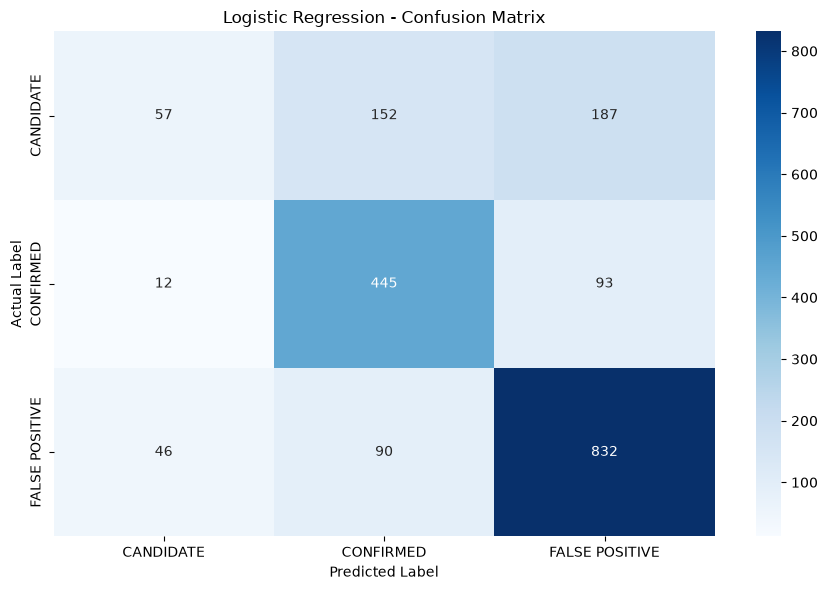

In [4]:
from sklearn.metrics import confusion_matrix

# Define class order
class_labels = [
    'CANDIDATE',
    'CONFIRMED',
    'FALSE POSITIVE'
]

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=class_labels
)

# Visualize confusion matrix
plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

In [5]:
# Initialize class-weighted Logistic Regression

lr_balanced = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

# Train the model
lr_balanced.fit(X_train, y_train)

# Generate predictions
y_pred_lr_balanced = lr_balanced.predict(X_test)

print("Class-weighted Logistic Regression trained!")

Class-weighted Logistic Regression trained!


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

# Calculate metrics
accuracy_bal = accuracy_score(y_test, y_pred_lr_balanced)

precision_bal = precision_score(
    y_test, y_pred_lr_balanced, average='macro'
)

recall_bal = recall_score(
    y_test, y_pred_lr_balanced, average='macro'
)

macro_f1_bal = f1_score(
    y_test, y_pred_lr_balanced, average='macro'
)

weighted_f1_bal = f1_score(
    y_test, y_pred_lr_balanced, average='weighted'
)

balanced_acc_bal = balanced_accuracy_score(
    y_test, y_pred_lr_balanced
)

print("CLASS-WEIGHTED LOGISTIC REGRESSION")
print("=" * 45)

print(f"Accuracy:          {accuracy_bal:.4f}")
print(f"Macro Precision:   {precision_bal:.4f}")
print(f"Macro Recall:      {recall_bal:.4f}")
print(f"Macro F1-score:    {macro_f1_bal:.4f}")
print(f"Weighted F1-score: {weighted_f1_bal:.4f}")
print(f"Balanced Accuracy: {balanced_acc_bal:.4f}")

print("\nCLASSIFICATION REPORT")
print("=" * 45)

print(classification_report(y_test, y_pred_lr_balanced))

CLASS-WEIGHTED LOGISTIC REGRESSION
Accuracy:          0.6641
Macro Precision:   0.6497
Macro Recall:      0.6601
Macro F1-score:    0.6411
Weighted F1-score: 0.6792
Balanced Accuracy: 0.6601

CLASSIFICATION REPORT
                precision    recall  f1-score   support

     CANDIDATE       0.38      0.56      0.45       396
     CONFIRMED       0.68      0.78      0.73       550
FALSE POSITIVE       0.89      0.64      0.75       968

      accuracy                           0.66      1914
     macro avg       0.65      0.66      0.64      1914
  weighted avg       0.72      0.66      0.68      1914



In [7]:
from sklearn.model_selection import StratifiedGroupKFold

# Load cleaned Kepler dataset
kepler_cv = pd.read_csv("../data/processed/kepler_clean.csv")

# Reconstruct the original numerical feature matrix
X_raw = kepler_cv[feature_names].copy()

# Target and host-star identifiers
y_raw = kepler_cv['koi_disposition'].copy()
groups_raw = kepler_cv['kepid'].copy()

# Recreate the same group-aware train-test split
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X_raw, y_raw, groups=groups_raw)
)

# Unscaled training features for cross-validation
X_train_raw = X_raw.iloc[train_idx].copy()
y_train_cv = y_raw.iloc[train_idx].copy()
groups_train_cv = groups_raw.iloc[train_idx].copy()

print("Raw training features:", X_train_raw.shape)
print("Training labels:", y_train_cv.shape)
print("Unique training stars:", groups_train_cv.nunique())

print("\nMissing values:", X_train_raw.isnull().sum().sum())

Raw training features: (7650, 31)
Training labels: (7650,)
Unique training stars: 6561

Missing values: 5848


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedGroupKFold

# Five-fold group-aware cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'macro_f1': 'f1_macro',
    'balanced_accuracy': 'balanced_accuracy'
}

# Model 1: Original Logistic Regression
lr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Model 2: Class-weighted Logistic Regression
lr_balanced_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ))
])

# Cross-validation: Original model
lr_cv_results = cross_validate(
    lr_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    scoring=scoring,
    n_jobs=-1
)

# Cross-validation: Balanced model
lr_balanced_cv_results = cross_validate(
    lr_balanced_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    scoring=scoring,
    n_jobs=-1
)

print("Cross-validation completed successfully!")

Cross-validation completed successfully!


In [9]:
cv_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Balanced Logistic Regression'
    ],

    'Accuracy Mean': [
        lr_cv_results['test_accuracy'].mean(),
        lr_balanced_cv_results['test_accuracy'].mean()
    ],

    'Macro F1 Mean': [
        lr_cv_results['test_macro_f1'].mean(),
        lr_balanced_cv_results['test_macro_f1'].mean()
    ],

    'Balanced Accuracy Mean': [
        lr_cv_results['test_balanced_accuracy'].mean(),
        lr_balanced_cv_results['test_balanced_accuracy'].mean()
    ],

    'Macro F1 Std': [
        lr_cv_results['test_macro_f1'].std(),
        lr_balanced_cv_results['test_macro_f1'].std()
    ]
})

print(cv_comparison.round(4).to_string(index=False))

                       Model  Accuracy Mean  Macro F1 Mean  Balanced Accuracy Mean  Macro F1 Std
         Logistic Regression         0.6926         0.5813                  0.6026        0.0152
Balanced Logistic Regression         0.6574         0.6353                  0.6547        0.0127


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate

# Decision Tree pipeline
dt_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),

    ('classifier', DecisionTreeClassifier(
        random_state=42
    ))
])

dt_overfit_results = cross_validate(
    dt_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    scoring={
        'accuracy': 'accuracy',
        'macro_f1': 'f1_macro'
    },
    return_train_score=True,
    n_jobs=-1
)

print("DECISION TREE OVERFITTING ANALYSIS")
print("=" * 45)

print("Training Accuracy:",
      round(dt_overfit_results['train_accuracy'].mean(), 4))

print("Validation Accuracy:",
      round(dt_overfit_results['test_accuracy'].mean(), 4))

print("Training Macro F1:",
      round(dt_overfit_results['train_macro_f1'].mean(), 4))

print("Validation Macro F1:",
      round(dt_overfit_results['test_macro_f1'].mean(), 4))

DECISION TREE OVERFITTING ANALYSIS
Training Accuracy: 1.0
Validation Accuracy: 0.7033
Training Macro F1: 1.0
Validation Macro F1: 0.6613


In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate

dt_configs = {
    "DT_depth_5": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "DT_depth_10": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),

    "DT_depth_15": DecisionTreeClassifier(
        max_depth=15,
        random_state=42
    ),

    "DT_regularized": DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    )
}

dt_tuning_results = []

for name, classifier in dt_configs.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train_raw,
        y_train_cv,
        cv=cv,
        groups=groups_train_cv,
        scoring={
            'accuracy': 'accuracy',
            'macro_f1': 'f1_macro',
            'balanced_accuracy': 'balanced_accuracy'
        },
        n_jobs=-1
    )

    dt_tuning_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Macro F1': scores['test_macro_f1'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean()
    })

dt_tuning_df = pd.DataFrame(dt_tuning_results)

dt_tuning_df.sort_values(
    by='Macro F1',
    ascending=False
)

,Model,Accuracy,Macro F1,Balanced Accuracy
3,DT_regularized,0.745491,0.706928,0.708790
1,DT_depth_10,0.744710,0.706441,0.708161
0,DT_depth_5,0.732818,0.692085,0.688853
2,DT_depth_15,0.719610,0.681415,0.684061


In [22]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),

    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_scores = cross_validate(
    rf_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    scoring={
        'accuracy': 'accuracy',
        'macro_f1': 'f1_macro',
        'balanced_accuracy': 'balanced_accuracy'
    },
    n_jobs=-1
)

print("RANDOM FOREST CROSS-VALIDATION")
print("=" * 45)

print("Accuracy:",
      round(rf_scores['test_accuracy'].mean(), 4))

print("Macro F1:",
      round(rf_scores['test_macro_f1'].mean(), 4))

print("Balanced Accuracy:",
      round(rf_scores['test_balanced_accuracy'].mean(), 4))

print("Macro F1 Std:",
      round(rf_scores['test_macro_f1'].std(), 4))

RANDOM FOREST CROSS-VALIDATION
Accuracy: 0.7846
Macro F1: 0.7409
Balanced Accuracy: 0.7378
Macro F1 Std: 0.0095


In [23]:
rf_overfit_results = cross_validate(
    rf_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    scoring={
        'accuracy': 'accuracy',
        'macro_f1': 'f1_macro'
    },
    return_train_score=True,
    n_jobs=-1
)

print("RANDOM FOREST OVERFITTING ANALYSIS")
print("=" * 45)

print("Training Accuracy:",
      round(rf_overfit_results['train_accuracy'].mean(), 4))

print("Validation Accuracy:",
      round(rf_overfit_results['test_accuracy'].mean(), 4))

print("Training Macro F1:",
      round(rf_overfit_results['train_macro_f1'].mean(), 4))

print("Validation Macro F1:",
      round(rf_overfit_results['test_macro_f1'].mean(), 4))

RANDOM FOREST OVERFITTING ANALYSIS
Training Accuracy: 1.0
Validation Accuracy: 0.7846
Training Macro F1: 1.0
Validation Macro F1: 0.7409


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate

rf_configs = {

    "RF_depth_10": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),

    "RF_depth_20": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "RF_regularized": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "RF_strong_regularization": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=20,
        min_samples_leaf=10,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
}

rf_tuning_results = []

for name, classifier in rf_configs.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train_raw,
        y_train_cv,
        cv=cv,
        groups=groups_train_cv,
        scoring={
            'accuracy': 'accuracy',
            'macro_f1': 'f1_macro',
            'balanced_accuracy': 'balanced_accuracy'
        },
        n_jobs=-1
    )

    rf_tuning_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Macro F1': scores['test_macro_f1'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'Macro F1 Std': scores['test_macro_f1'].std()
    })

rf_tuning_df = pd.DataFrame(rf_tuning_results)

rf_tuning_df.sort_values(
    by='Macro F1',
    ascending=False
)

,Model,Accuracy,Macro F1,Balanced Accuracy,Macro F1 Std
1,RF_depth_20,0.786669,0.742867,0.739553,0.008797
2,RF_regularized,0.784449,0.739501,0.735812,0.009640
0,RF_depth_10,0.782228,0.736403,0.734374,0.010606
3,RF_strong_regularization,0.780526,0.733235,0.728973,0.007853


In [26]:
rf_best = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

In [27]:
rf_best_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', rf_best)
])

rf_best_overfit = cross_validate(
    rf_best_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    scoring={
        'accuracy': 'accuracy',
        'macro_f1': 'f1_macro'
    },
    return_train_score=True,
    n_jobs=-1
)

print("TUNED RANDOM FOREST OVERFITTING ANALYSIS")
print("=" * 50)

print("Training Accuracy:",
      round(rf_best_overfit['train_accuracy'].mean(), 4))

print("Validation Accuracy:",
      round(rf_best_overfit['test_accuracy'].mean(), 4))

print("Training Macro F1:",
      round(rf_best_overfit['train_macro_f1'].mean(), 4))

print("Validation Macro F1:",
      round(rf_best_overfit['test_macro_f1'].mean(), 4))

TUNED RANDOM FOREST OVERFITTING ANALYSIS
Training Accuracy: 0.9987
Validation Accuracy: 0.7867
Training Macro F1: 0.9985
Validation Macro F1: 0.7429


In [28]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        random_state=42
    ))
])

svm_scores = cross_validate(
    svm_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    scoring={
        'accuracy': 'accuracy',
        'macro_f1': 'f1_macro',
        'balanced_accuracy': 'balanced_accuracy'
    },
    n_jobs=-1
)

print("SVM CROSS-VALIDATION")
print("=" * 40)

print("Accuracy:",
      round(svm_scores['test_accuracy'].mean(), 4))

print("Macro F1:",
      round(svm_scores['test_macro_f1'].mean(), 4))

print("Balanced Accuracy:",
      round(svm_scores['test_balanced_accuracy'].mean(), 4))

print("Macro F1 Std:",
      round(svm_scores['test_macro_f1'].std(), 4))

SVM CROSS-VALIDATION
Accuracy: 0.6978
Macro F1: 0.5688
Balanced Accuracy: 0.5978
Macro F1 Std: 0.0054


In [29]:
from sklearn.svm import SVC

svm_configs = {
    "SVM_C0.1": SVC(
        kernel='rbf', C=0.1, gamma='scale'
    ),

    "SVM_C1": SVC(
        kernel='rbf', C=1, gamma='scale'
    ),

    "SVM_C10": SVC(
        kernel='rbf', C=10, gamma='scale'
    ),

    "SVM_C10_gamma0.01": SVC(
        kernel='rbf', C=10, gamma=0.01
    ),

    "SVM_C10_gamma0.1": SVC(
        kernel='rbf', C=10, gamma=0.1
    ),

    "SVM_C100_gamma0.01": SVC(
        kernel='rbf', C=100, gamma=0.01
    )
}

svm_tuning_results = []

for name, classifier in svm_configs.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train_raw,
        y_train_cv,
        cv=cv,
        groups=groups_train_cv,
        scoring={
            'accuracy': 'accuracy',
            'macro_f1': 'f1_macro',
            'balanced_accuracy': 'balanced_accuracy'
        },
        n_jobs=-1
    )

    svm_tuning_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Macro F1': scores['test_macro_f1'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'Macro F1 Std': scores['test_macro_f1'].std()
    })

svm_tuning_df = pd.DataFrame(svm_tuning_results)

svm_tuning_df.sort_values(
    by='Macro F1',
    ascending=False
)

,Model,Accuracy,Macro F1,Balanced Accuracy,Macro F1 Std
4,SVM_C10_gamma0.1,0.698300,0.620968,0.627143,0.011940
5,SVM_C100_gamma0.01,0.712294,0.619899,0.634080,0.008711
2,SVM_C10,0.704582,0.609211,0.623702,0.010354
3,SVM_C10_gamma0.01,0.706672,0.597456,0.618222,0.006576
1,SVM_C1,0.697780,0.568837,0.597792,0.005357
0,SVM_C0.1,0.674642,0.496543,0.550638,0.008213


In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate

knn_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        weights='uniform',
        metric='minkowski'
    ))
])

knn_cv_results = cross_validate(
    knn_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    scoring=scoring,
    n_jobs=-1
)

print("KNN Cross-Validation Results")
print("-" * 40)

for metric in scoring:
    scores = knn_cv_results[f'test_{metric}']
    print(f"{metric}: {scores.mean():.4f} ± {scores.std():.4f}")

KNN Cross-Validation Results
----------------------------------------
accuracy: 0.6421 ± 0.0112
macro_f1: 0.5813 ± 0.0145
balanced_accuracy: 0.5863 ± 0.0147


In [31]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate

knn_configs = {
    "KNN_3_uniform": KNeighborsClassifier(
        n_neighbors=3, weights='uniform'
    ),
    "KNN_5_uniform": KNeighborsClassifier(
        n_neighbors=5, weights='uniform'
    ),
    "KNN_7_uniform": KNeighborsClassifier(
        n_neighbors=7, weights='uniform'
    ),
    "KNN_11_uniform": KNeighborsClassifier(
        n_neighbors=11, weights='uniform'
    ),
    "KNN_15_uniform": KNeighborsClassifier(
        n_neighbors=15, weights='uniform'
    ),
    "KNN_5_distance": KNeighborsClassifier(
        n_neighbors=5, weights='distance'
    ),
    "KNN_11_distance": KNeighborsClassifier(
        n_neighbors=11, weights='distance'
    ),
    "KNN_15_distance": KNeighborsClassifier(
        n_neighbors=15, weights='distance'
    ),
}

knn_tuning_results = []

for name, classifier in knn_configs.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train_raw,
        y_train_cv,
        cv=cv,
        groups=groups_train_cv,
        scoring=scoring,
        n_jobs=-1
    )

    knn_tuning_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Macro F1': scores['test_macro_f1'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'Macro F1 Std': scores['test_macro_f1'].std()
    })

knn_results_df = pd.DataFrame(knn_tuning_results)

knn_results_df = knn_results_df.sort_values(
    by='Macro F1',
    ascending=False
).reset_index(drop=True)

knn_results_df

,Model,Accuracy,Macro F1,Balanced Accuracy,Macro F1 Std
0,KNN_11_uniform,0.666271,0.588473,0.598055,0.009630
1,KNN_11_distance,0.673330,0.586507,0.597765,0.011436
2,KNN_7_uniform,0.654770,0.582949,0.589374,0.006886
3,KNN_15_uniform,0.668365,0.582230,0.594511,0.009170
4,KNN_5_uniform,0.642088,0.581275,0.586344,0.014480
5,KNN_15_distance,0.673855,0.578984,0.594080,0.009786
6,KNN_5_distance,0.652547,0.578840,0.583893,0.012722
7,KNN_3_uniform,0.630325,0.574696,0.575319,0.006715


In [32]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
    print("XGBoost is ready!")
except ImportError:
    print("XGBoost is not installed.")

XGBoost is not installed.


In [33]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB 660.6 kB/s eta 0:01:15
   ---------------------------------------- 0.0/48.9 MB 660.6 kB/s eta 0:01:15
   ---------------------------------------- 0.1/48.9 MB 491.5 kB/s eta 0:01:40
   ---------------------------------------- 0.1/48.9 MB 722.1 kB/s eta 0:01:08
   ---------------------------------------- 0.2/48.9 MB 958.4 kB/s eta 0:00:51
   ---------------------------------------- 0.2/48.9 MB 958.4 kB/s eta 0:00:51
   ---------------------------------------- 0.2/48.9 MB 765.3 kB/s eta 0:01:04
   ---------------------------------------- 0.4/48.9 MB 1.0 MB/s eta 0:00:49
   ---------------------------------------- 0.5/48.9 MB 1.1 MB/s eta 0:00:43
   ---------------------------------------- 0.6/48.9 MB 1.2 MB/s eta 0:00:40
    --------------------------------------- 0.6/48.9 MB 1.2 MB/s eta 0:00:40


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("XGBoost is ready!")

XGBoost version: 3.4.1
XGBoost is ready!


In [36]:
from sklearn.preprocessing import LabelEncoder

xgb_label_encoder = LabelEncoder()

y_train_xgb = xgb_label_encoder.fit_transform(y_train_cv)

print("Class mapping:")

for class_name, encoded_value in zip(
    xgb_label_encoder.classes_,
    xgb_label_encoder.transform(xgb_label_encoder.classes_)
):
    print(f"{class_name} -> {encoded_value}")

print("\nEncoded target distribution:")
print(pd.Series(y_train_xgb).value_counts().sort_index())

Class mapping:
CANDIDATE -> 0
CONFIRMED -> 1
FALSE POSITIVE -> 2

Encoded target distribution:
0    1581
1    2198
2    3871
Name: count, dtype: int64


In [37]:
xgb_cv_results = cross_validate(
    xgb_pipeline,
    X_train_raw,
    y_train_xgb,
    cv=cv,
    groups=groups_train_cv,
    scoring=scoring,
    n_jobs=1
)

print("XGBoost Baseline Cross-Validation Results")
print("-" * 50)

for metric in scoring:
    scores = xgb_cv_results[f'test_{metric}']
    print(f"{metric}: {scores.mean():.4f} ± {scores.std():.4f}")

XGBoost Baseline Cross-Validation Results
--------------------------------------------------
accuracy: 0.7871 ± 0.0054
macro_f1: 0.7426 ± 0.0058
balanced_accuracy: 0.7412 ± 0.0061


In [38]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate

xgb_configs = {

    "XGB_depth3": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    ),

    "XGB_depth5": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    ),

    "XGB_depth7": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=7,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    ),

    "XGB_depth5_subsample": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    ),

    "XGB_depth5_regularized": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        min_child_weight=5,
        reg_lambda=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    ),

    "XGB_depth3_fast": XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    )
}

xgb_tuning_results = []

for name, classifier in xgb_configs.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train_raw,
        y_train_xgb,
        cv=cv,
        groups=groups_train_cv,
        scoring=scoring,
        n_jobs=1
    )

    xgb_tuning_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Macro F1': scores['test_macro_f1'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'Macro F1 Std': scores['test_macro_f1'].std()
    })

xgb_results_df = pd.DataFrame(xgb_tuning_results)

xgb_results_df = xgb_results_df.sort_values(
    by='Macro F1',
    ascending=False
).reset_index(drop=True)

xgb_results_df

,Model,Accuracy,Macro F1,Balanced Accuracy,Macro F1 Std
0,XGB_depth5_regularized,0.791376,0.748116,0.746056,0.007765
1,XGB_depth3_fast,0.788113,0.745789,0.744466,0.012122
2,XGB_depth5_subsample,0.787848,0.743825,0.742172,0.012727
3,XGB_depth5,0.787062,0.742586,0.741175,0.005824
4,XGB_depth7,0.786539,0.742174,0.740363,0.008320
5,XGB_depth3,0.781182,0.736216,0.734424,0.009223


In [39]:
xgb_refined_configs = {

    "XGB_300_lr003": XGBClassifier(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=5,
        min_child_weight=5,
        reg_lambda=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    ),

    "XGB_500_lr003": XGBClassifier(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=5,
        min_child_weight=5,
        reg_lambda=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    ),

    "XGB_500_lr005": XGBClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        min_child_weight=5,
        reg_lambda=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    ),

    "XGB_300_lr007": XGBClassifier(
        n_estimators=300,
        learning_rate=0.07,
        max_depth=5,
        min_child_weight=5,
        reg_lambda=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    ),

    "XGB_300_more_regularization": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        min_child_weight=10,
        reg_lambda=10,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    )
}

xgb_refined_results = []

for name, classifier in xgb_refined_configs.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train_raw,
        y_train_xgb,
        cv=cv,
        groups=groups_train_cv,
        scoring=scoring,
        n_jobs=1
    )

    xgb_refined_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Macro F1': scores['test_macro_f1'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'Macro F1 Std': scores['test_macro_f1'].std()
    })

xgb_refined_df = pd.DataFrame(xgb_refined_results)

xgb_refined_df = xgb_refined_df.sort_values(
    by='Macro F1',
    ascending=False
).reset_index(drop=True)

xgb_refined_df

,Model,Accuracy,Macro F1,Balanced Accuracy,Macro F1 Std
0,XGB_500_lr005,0.790722,0.747824,0.746267,0.006546
1,XGB_300_more_regularization,0.790462,0.747737,0.745951,0.009492
2,XGB_300_lr003,0.791638,0.747523,0.745511,0.005025
3,XGB_300_lr007,0.789548,0.746928,0.745476,0.012713
4,XGB_500_lr003,0.790594,0.746789,0.744751,0.009057


In [40]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate

et_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', ExtraTreesClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

et_cv_results = cross_validate(
    et_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    scoring=scoring,
    n_jobs=1
)

print("Extra Trees Cross-Validation Results")
print("-" * 45)

for metric in scoring:
    scores = et_cv_results[f'test_{metric}']
    print(f"{metric}: {scores.mean():.4f} ± {scores.std():.4f}")

Extra Trees Cross-Validation Results
---------------------------------------------
accuracy: 0.7511 ± 0.0022
macro_f1: 0.6824 ± 0.0075
balanced_accuracy: 0.6840 ± 0.0067


In [41]:
%pip install catboost

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.1/100.2 MB 1.3 MB/s eta 0:01:17
   ---------------------------------------- 0.2/100.2 MB 1.1 MB/s eta 0:01:30
   ---------------------------------------- 0.3/100.2 MB 1.2 MB/s eta 0:01:23
   ---------------------------------------- 0.3/100.2 MB 1.2 MB/s eta 0:01:22
   ---------------------------------------- 0.4/100.2 MB 1.3 MB/s eta 0:01:19
   ---------------------------------------- 0.5/100.2 MB 1.3 MB/s eta 0:01:18
   ---------------------------------------- 0.5/100.2 MB 1.3 MB/s eta 0:01:18
   ---------------------------------------- 0.6/100.2 MB 1.3 MB/s eta 0:01:15
   ---------------------------------------- 0.6/100.2 MB 1.3 MB/s eta 0:01:15
   ---------------------------------------- 0.6/100.2 MB 1.3 MB/s eta 0:01:15
   ---------------------------------------- 0.8/100.2 MB 1.3 MB/s eta 0:01:15


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
import catboost

print("CatBoost version:", catboost.__version__)

CatBoost version: 1.2.10


In [43]:
from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate

print("CatBoost imported successfully!")

CatBoost imported successfully!


In [44]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        l2_leaf_reg=5,
        loss_function='MultiClass',
        random_seed=42,
        verbose=0,
        thread_count=-1
    ))
])

In [45]:
cat_cv_results = cross_validate(
    cat_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    scoring=scoring,
    n_jobs=1
)

print("CatBoost Cross-Validation Results")
print("-" * 45)

for metric in scoring:
    scores = cat_cv_results[f'test_{metric}']
    print(f"{metric}: {scores.mean():.4f} ± {scores.std():.4f}")

CatBoost Cross-Validation Results
---------------------------------------------
accuracy: 0.7895 ± 0.0103
macro_f1: 0.7471 ± 0.0119
balanced_accuracy: 0.7445 ± 0.0123


In [46]:
cat_configs = {
    "CatBoost_depth4": CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=4,
        l2_leaf_reg=5,
        loss_function='MultiClass',
        random_seed=42,
        verbose=0,
        thread_count=-1
    ),

    "CatBoost_depth8": CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=8,
        l2_leaf_reg=5,
        loss_function='MultiClass',
        random_seed=42,
        verbose=0,
        thread_count=-1
    ),

    "CatBoost_regularized": CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        l2_leaf_reg=10,
        loss_function='MultiClass',
        random_seed=42,
        verbose=0,
        thread_count=-1
    ),

    "CatBoost_more_iterations": CatBoostClassifier(
        iterations=800,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=5,
        loss_function='MultiClass',
        random_seed=42,
        verbose=0,
        thread_count=-1
    )
}

In [47]:
cat_tuning_results = []

for name, model in cat_configs.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', model)
    ])

    scores = cross_validate(
        pipeline,
        X_train_raw,
        y_train_cv,
        cv=cv,
        groups=groups_train_cv,
        scoring=scoring,
        n_jobs=1
    )

    cat_tuning_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Macro F1': scores['test_macro_f1'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'Macro F1 Std': scores['test_macro_f1'].std()
    })

cat_tuning_df = pd.DataFrame(cat_tuning_results)

cat_tuning_df.sort_values(
    by='Macro F1',
    ascending=False
)

,Model,Accuracy,Macro F1,Balanced Accuracy,Macro F1 Std
1,CatBoost_depth8,0.792555,0.749170,0.746020,0.012600
3,CatBoost_more_iterations,0.788240,0.744372,0.741790,0.007421
2,CatBoost_regularized,0.787585,0.743577,0.740269,0.010932
0,CatBoost_depth4,0.786801,0.743191,0.740757,0.010704


In [48]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from catboost import CatBoostClassifier

cat_best_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=8,
        l2_leaf_reg=5,
        loss_function='MultiClass',
        random_seed=42,
        verbose=0,
        thread_count=-1
    ))
])

cat_oof_predictions = cross_val_predict(
    cat_best_pipeline,
    X_train_raw,
    y_train_cv,
    cv=cv,
    groups=groups_train_cv,
    n_jobs=1
)

print("CatBoost Depth 8 - Out-of-Fold Classification Report")
print("-" * 60)

print(classification_report(
    y_train_cv,
    cat_oof_predictions,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_train_cv,
    cat_oof_predictions,
    labels=['CANDIDATE', 'CONFIRMED', 'FALSE POSITIVE']
))

CatBoost Depth 8 - Out-of-Fold Classification Report
------------------------------------------------------------
                precision    recall  f1-score   support

     CANDIDATE     0.6188    0.4991    0.5525      1581
     CONFIRMED     0.8237    0.8712    0.8468      2198
FALSE POSITIVE     0.8294    0.8677    0.8481      3871

      accuracy                         0.7925      7650
     macro avg     0.7573    0.7460    0.7491      7650
  weighted avg     0.7842    0.7925    0.7866      7650

Confusion Matrix:
[[ 789  234  558]
 [ 150 1915  133]
 [ 336  176 3359]]


In [49]:
cat_final_candidate = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=8,
        l2_leaf_reg=5,
        loss_function='MultiClass',
        random_seed=42,
        verbose=0,
        thread_count=-1
    ))
])

cat_final_candidate.fit(X_train_raw, y_train_cv)

print("CatBoost training completed!")

CatBoost training completed!


In [50]:
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': cat_final_candidate.named_steps[
        'classifier'
    ].feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
16,koi_model_snr,18.359144
8,koi_prad,9.345394
6,koi_ror,5.921706
20,koi_smet,5.748068
3,koi_impact,5.344099
13,koi_dor,5.284317
4,koi_duration,5.042556
17,koi_count,4.662904
7,koi_srho,4.355922
0,koi_period,3.772003


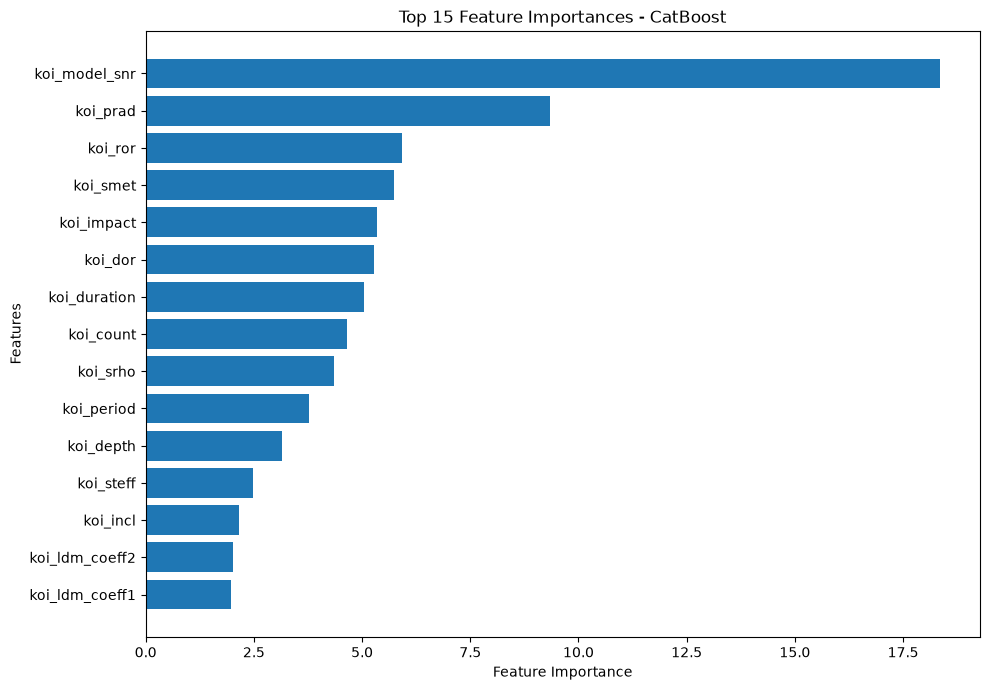

In [51]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 15 Feature Importances - CatBoost')

plt.tight_layout()
plt.show()

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Reconstruct the original test data
X_test_raw = X_raw.iloc[test_idx].copy()
y_test_final = y_raw.iloc[test_idx].copy()

# Predict using the trained CatBoost pipeline
y_test_pred = cat_final_candidate.predict(X_test_raw)

# Evaluation
print("FINAL CATBOOST TEST RESULTS")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test_final, y_test_pred))
print("Macro Precision:", precision_score(
    y_test_final, y_test_pred, average='macro'
))
print("Macro Recall:", recall_score(
    y_test_final, y_test_pred, average='macro'
))
print("Macro F1:", f1_score(
    y_test_final, y_test_pred, average='macro'
))
print("Balanced Accuracy:", balanced_accuracy_score(
    y_test_final, y_test_pred
))

print("\nClassification Report:")
print(classification_report(
    y_test_final, y_test_pred, digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_final,
    y_test_pred,
    labels=['CANDIDATE', 'CONFIRMED', 'FALSE POSITIVE']
))

FINAL CATBOOST TEST RESULTS
Accuracy: 0.7946708463949843
Macro Precision: 0.7615740809423673
Macro Recall: 0.7497229874502601
Macro F1: 0.7526988234449726
Balanced Accuracy: 0.7497229874502601

Classification Report:
                precision    recall  f1-score   support

     CANDIDATE     0.6274    0.4975    0.5549       396
     CONFIRMED     0.8330    0.8891    0.8602       550
FALSE POSITIVE     0.8243    0.8626    0.8430       968

      accuracy                         0.7947      1914
     macro avg     0.7616    0.7497    0.7527      1914
  weighted avg     0.7861    0.7947    0.7883      1914


Confusion Matrix:
[[197  52 147]
 [ 30 489  31]
 [ 87  46 835]]


In [53]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

model_bundle = {
    "pipeline": cat_final_candidate,
    "feature_names": feature_names,
    "target_classes": [
        "CANDIDATE",
        "CONFIRMED",
        "FALSE POSITIVE"
    ],
    "model_name": "CatBoost",
    "test_macro_f1": 0.7526988234449726
}

joblib.dump(
    model_bundle,
    "../models/exodetect_catboost_final.pkl"
)

print("Final model saved successfully!")


Final model saved successfully!
